# Parte Específica — EDA do dataset Hepatitis C

Diagnóstico de qualidade no dado bruto (estrutura, ausentes e outliers) e análise de distribuições e relações
no dado preparado por `preparacao.py`.

Fonte: *HCV data*, UCI Machine Learning Repository (Lichtinghagen, Klawonn e Hoffmann, 2020), licença CC BY 4.0.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import config
import preparacao

config.DIR_FIGURAS.mkdir(parents=True, exist_ok=True)

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', None)

PALETA = config.CORES_CATEGORIA


def salvar(fig, nome):
    fig.savefig(config.DIR_FIGURAS / f'{nome}.png', dpi=150, bbox_inches='tight')

## 1. Visão estrutural do bruto

In [2]:
bruto = preparacao.separar_categoria(preparacao.renomear_colunas(preparacao.carregar_bruto()))
print(f'{bruto.shape[0]} linhas x {bruto.shape[1]} colunas')
bruto.head()

615 linhas x 14 colunas


,categoria,idade,sexo,alb,alp,alt,ast,bil,che,chol,crea,ggt,prot,categoria_cod
1,Blood Donor,32,m,38.5,52.5,7.7,22.1,7.5,6.93,3.23,106.0,12.1,69.0,0
2,Blood Donor,32,m,38.5,70.3,18.0,24.7,3.9,11.17,4.80,74.0,15.6,76.5,0
3,Blood Donor,32,m,46.9,74.7,36.2,52.6,6.1,8.84,5.20,86.0,33.2,79.3,0
4,Blood Donor,32,m,43.2,52.0,30.6,22.6,18.9,7.33,4.74,80.0,33.8,75.7,0
5,Blood Donor,32,m,39.2,74.1,32.6,24.8,9.6,9.15,4.32,76.0,29.9,68.7,0


In [3]:
bruto.info()

<class 'pandas.DataFrame'>
RangeIndex: 615 entries, 1 to 615
Data columns (total 14 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   categoria      615 non-null    str    
 1   idade          615 non-null    int64  
 2   sexo           615 non-null    str    
 3   alb            614 non-null    float64
 4   alp            597 non-null    float64
 5   alt            614 non-null    float64
 6   ast            615 non-null    float64
 7   bil            615 non-null    float64
 8   che            615 non-null    float64
 9   chol           605 non-null    float64
 10  crea           615 non-null    float64
 11  ggt            615 non-null    float64
 12  prot           614 non-null    float64
 13  categoria_cod  615 non-null    str    
dtypes: float64(10), int64(1), str(3)
memory usage: 75.1 KB


In [4]:
pd.DataFrame({
    'tipo': bruto.dtypes.astype(str),
    'n_unicos': bruto.nunique(),
    'ausentes': bruto.isna().sum(),
})

,tipo,n_unicos,ausentes
categoria,str,5,0
idade,int64,49,0
sexo,str,2,0
alb,float64,189,1
alp,float64,414,18
alt,float64,341,1
ast,float64,297,0
bil,float64,188,0
che,float64,407,0
chol,float64,313,10


In [5]:
print(f'Linhas duplicadas: {bruto.duplicated().sum()}')

tabela_cat = pd.crosstab(bruto['categoria'], bruto['sexo'], margins=True, margins_name='total')
tabela_cat['pct_total'] = (tabela_cat['total'] / len(bruto) * 100).round(1)
tabela_cat['linhas_com_ausente'] = bruto.groupby('categoria')[config.COLS_EXAMES].apply(
    lambda g: g.isna().any(axis=1).sum()
).reindex(tabela_cat.index)
tabela_cat.reindex(config.ORDEM_CATEGORIAS + ['total'])

Linhas duplicadas: 0


sexo,f,m,total,pct_total,linhas_com_ausente
categoria,,,,,
Blood Donor,215,318,533,86.7,7.0
suspect Blood Donor,1,6,7,1.1,0.0
Hepatitis,4,20,24,3.9,4.0
Fibrosis,8,13,21,3.4,9.0
Cirrhosis,10,20,30,4.9,6.0
total,238,377,615,100.0,NaN


In [6]:
bruto[config.COLS_QUANTITATIVAS].describe().T.assign(
    assimetria=bruto[config.COLS_QUANTITATIVAS].skew()
).round(2)

,count,mean,std,min,25%,50%,75%,max,assimetria
idade,615.0,47.41,10.06,19.00,39.00,47.00,54.00,77.00,0.27
alb,614.0,41.62,5.78,14.90,38.80,41.95,45.20,82.20,-0.18
alp,597.0,68.28,26.03,11.30,52.50,66.20,80.10,416.60,4.65
alt,614.0,28.45,25.47,0.90,16.40,23.00,33.08,325.30,5.51
ast,615.0,34.79,33.09,10.60,21.60,25.90,32.90,324.00,4.94
bil,615.0,11.40,19.67,0.80,5.30,7.30,11.20,254.00,8.39
che,615.0,8.20,2.21,1.42,6.94,8.26,9.59,16.41,-0.11
chol,605.0,5.37,1.13,1.43,4.61,5.30,6.06,9.67,0.38
crea,615.0,81.29,49.76,8.00,67.00,77.00,88.00,1079.10,15.17
ggt,615.0,39.53,54.66,4.50,15.70,23.30,40.20,650.90,5.63


**Análise do grupo:**

_(escrever aqui)_

## 2. Ausentes e mecanismo de ausência

Para investigar o mecanismo (MCAR, MAR ou MNAR), o indicador de ausência de cada exame é cruzado com
o diagnóstico, o sexo, a idade e os demais exames.

In [7]:
cols_com_ausente = [c for c in config.COLS_EXAMES if bruto[c].isna().any()]
ausente = bruto[cols_com_ausente].isna()

print(f'{int(ausente.sum().sum())} células ausentes em {int(ausente.any(axis=1).sum())} linhas '
      f'({ausente.any(axis=1).mean():.1%} das linhas)')
ausente.sum().to_frame('n_ausentes')

31 células ausentes em 26 linhas (4.2% das linhas)


,n_ausentes
alb,1
alp,18
alt,1
chol,10
prot,1


In [8]:
print('Linhas com mais de um exame ausente:')
bruto.loc[ausente.sum(axis=1) > 1, ['categoria', 'sexo', 'idade'] + cols_com_ausente]

Linhas com mais de um exame ausente:


,categoria,sexo,idade,alb,alp,alt,chol,prot
585,Fibrosis,f,75,36.0,NaN,114.0,NaN,72.0
591,Cirrhosis,m,46,20.0,NaN,62.0,NaN,NaN
604,Cirrhosis,m,65,NaN,NaN,40.0,NaN,79.0


### Ausência × diagnóstico

In [9]:
contagem = ausente.groupby(bruto['categoria']).sum().reindex(config.ORDEM_CATEGORIAS)
contagem['n_linhas'] = bruto['categoria'].value_counts().reindex(config.ORDEM_CATEGORIAS)
contagem

,alb,alp,alt,chol,prot,n_linhas
categoria,,,,,,
Blood Donor,0,0,0,7,0,533
suspect Blood Donor,0,0,0,0,0,7
Hepatitis,0,3,1,0,0,24
Fibrosis,0,9,0,1,0,21
Cirrhosis,1,6,0,2,1,30


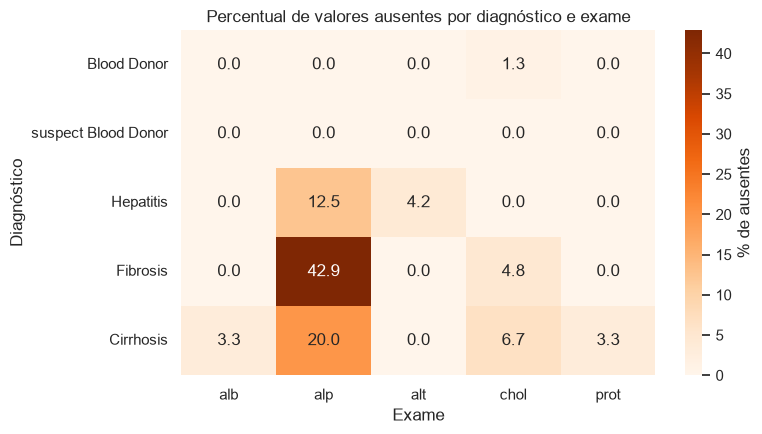

In [10]:
pct = ausente.groupby(bruto['categoria']).mean().reindex(config.ORDEM_CATEGORIAS) * 100

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.heatmap(pct, annot=True, fmt='.1f', cmap='Oranges', ax=ax, cbar_kws={'label': '% de ausentes'})
ax.set_title('Percentual de valores ausentes por diagnóstico e exame')
ax.set_xlabel('Exame')
ax.set_ylabel('Diagnóstico')
fig.tight_layout()
salvar(fig, 'eda_ausentes_por_diagnostico')
plt.show()

### Ausência × sexo e idade

In [11]:
pd.concat({
    'ausentes_por_sexo': ausente.groupby(bruto['sexo']).sum().T,
    'pct_por_sexo': (ausente.groupby(bruto['sexo']).mean().T * 100).round(1),
}, axis=1)

ausentes_por_sexo     pct_por_sexo     
sexo                 f   m            f    m
alb                  0   1          0.0  0.3
alp                  6  12          2.5  3.2
alt                  0   1          0.0  0.3
chol                 7   3          2.9  0.8
prot                 0   1          0.0  0.3

In [12]:
linhas = []
for col in cols_com_ausente:
    idades = bruto.groupby(ausente[col])['idade']
    linhas.append({
        'exame': col,
        'idade_media_com_valor': idades.mean().get(False),
        'idade_media_ausente': idades.mean().get(True),
        'n_ausente': int(ausente[col].sum()),
    })
pd.DataFrame(linhas).set_index('exame').round(1)

,idade_media_com_valor,idade_media_ausente,n_ausente
exame,,,
alb,47.4,65.0,1
alp,47.4,49.0,18
alt,47.4,38.0,1
chol,47.4,49.3,10
prot,47.4,46.0,1


### Ausência × demais exames

Mediana dos outros exames nas linhas em que o exame da linha está ausente, comparada com as linhas em que ele foi medido.

In [13]:
comparacoes = {}
for col in cols_com_ausente:
    outros = [c for c in config.COLS_EXAMES if c != col]
    medianas = bruto.groupby(ausente[col])[outros].median().T
    medianas.columns = medianas.columns.map({False: 'medido', True: 'ausente'})
    comparacoes[col] = medianas
pd.concat(comparacoes, axis=1).round(2)

alb            alp            alt           chol           prot  \
alb  medido ausente medido ausente medido ausente medido ausente medido   
alp   66.20     NaN    NaN     NaN  66.25   56.30  66.20   93.30  66.20   
alt   23.00    40.0  22.50   90.50    NaN     NaN  23.00   17.15  23.00   
ast   25.90    54.0  25.70   64.50  25.90   33.10  25.80   39.30  25.90   
bil    7.30    13.0   7.10   13.50   7.30    7.00   7.30    4.95   7.30   
che    8.26     7.5   8.27    7.65   8.26    9.58   8.26    8.30   8.26   
chol   5.30     NaN   5.31    4.20   5.30    6.00    NaN     NaN   5.30   
crea  77.00    70.0  77.00   72.00  76.85   77.90  77.00   63.00  76.85   
ggt   23.30   107.0  22.90   75.50  23.30   18.90  23.20   27.35  23.30   
prot  72.20    79.0  72.10   77.00  72.20   63.00  72.20   72.40    NaN   
alb     NaN     NaN  42.00   39.00  41.90   45.00  41.90   45.60  42.00   

              
alb  ausente  
alp      NaN  
alt    62.00  
ast   113.00  
bil   254.00  
che     1.48  
chol     NaN  
crea  114.00  
ggt   138.00  
prot     NaN  
alb    20.00

**Análise do grupo:**

_(escrever aqui)_

**Decisão do grupo sobre os ausentes:** mecanismo identificado e tratamento escolhido
(`ESTRATEGIA_AUSENTES` em `preparacao.py`), com justificativa.

_(escrever aqui)_

## 3. Outliers

In [14]:
def resumo_outliers(dados, cols):
    linhas = []
    for col in cols:
        q1, q3 = dados[col].quantile([0.25, 0.75])
        iqr = q3 - q1
        fora = (dados[col] < q1 - 1.5 * iqr) | (dados[col] > q3 + 1.5 * iqr)
        z = (dados[col] - dados[col].mean()) / dados[col].std()
        linhas.append({
            'variavel': col,
            'mediana': dados[col].median(),
            'maximo': dados[col].max(),
            'lim_inf_iqr': q1 - 1.5 * iqr,
            'lim_sup_iqr': q3 + 1.5 * iqr,
            'n_iqr': int(fora.sum()),
            'n_z_maior_3': int((z.abs() > 3).sum()),
        })
    return pd.DataFrame(linhas).set_index('variavel').round(2)


tabela_outliers = resumo_outliers(bruto, config.COLS_QUANTITATIVAS)
tabela_outliers

,mediana,maximo,lim_inf_iqr,lim_sup_iqr,n_iqr,n_z_maior_3
variavel,,,,,,
idade,47.00,77.00,16.50,76.50,1,0
alb,41.95,82.20,29.20,54.80,27,13
alp,66.20,416.60,11.10,121.50,10,3
alt,23.00,325.30,-8.61,58.09,36,10
ast,25.90,324.00,4.65,49.85,64,14
bil,7.30,254.00,-3.55,20.05,47,7
che,8.26,16.41,2.95,13.57,24,9
chol,5.30,9.67,2.44,8.24,12,7
crea,77.00,1079.10,35.50,119.50,12,3


### Em quais diagnósticos estão os outliers (regra de 1,5 × IQR)

In [15]:
fora_iqr = pd.DataFrame({
    col: (bruto[col] < tabela_outliers.loc[col, 'lim_inf_iqr'])
         | (bruto[col] > tabela_outliers.loc[col, 'lim_sup_iqr'])
    for col in config.COLS_EXAMES
})
fora_iqr.groupby(bruto['categoria']).sum().reindex(config.ORDEM_CATEGORIAS)

,alb,alp,alt,ast,bil,che,chol,crea,ggt,prot
categoria,,,,,,,,,,
Blood Donor,13,4,19,10,23,7,9,2,29,8
suspect Blood Donor,6,2,3,3,0,1,0,4,4,6
Hepatitis,0,0,3,11,4,2,1,1,7,2
Fibrosis,0,0,7,15,2,0,0,0,9,0
Cirrhosis,8,4,4,25,18,14,2,5,16,4


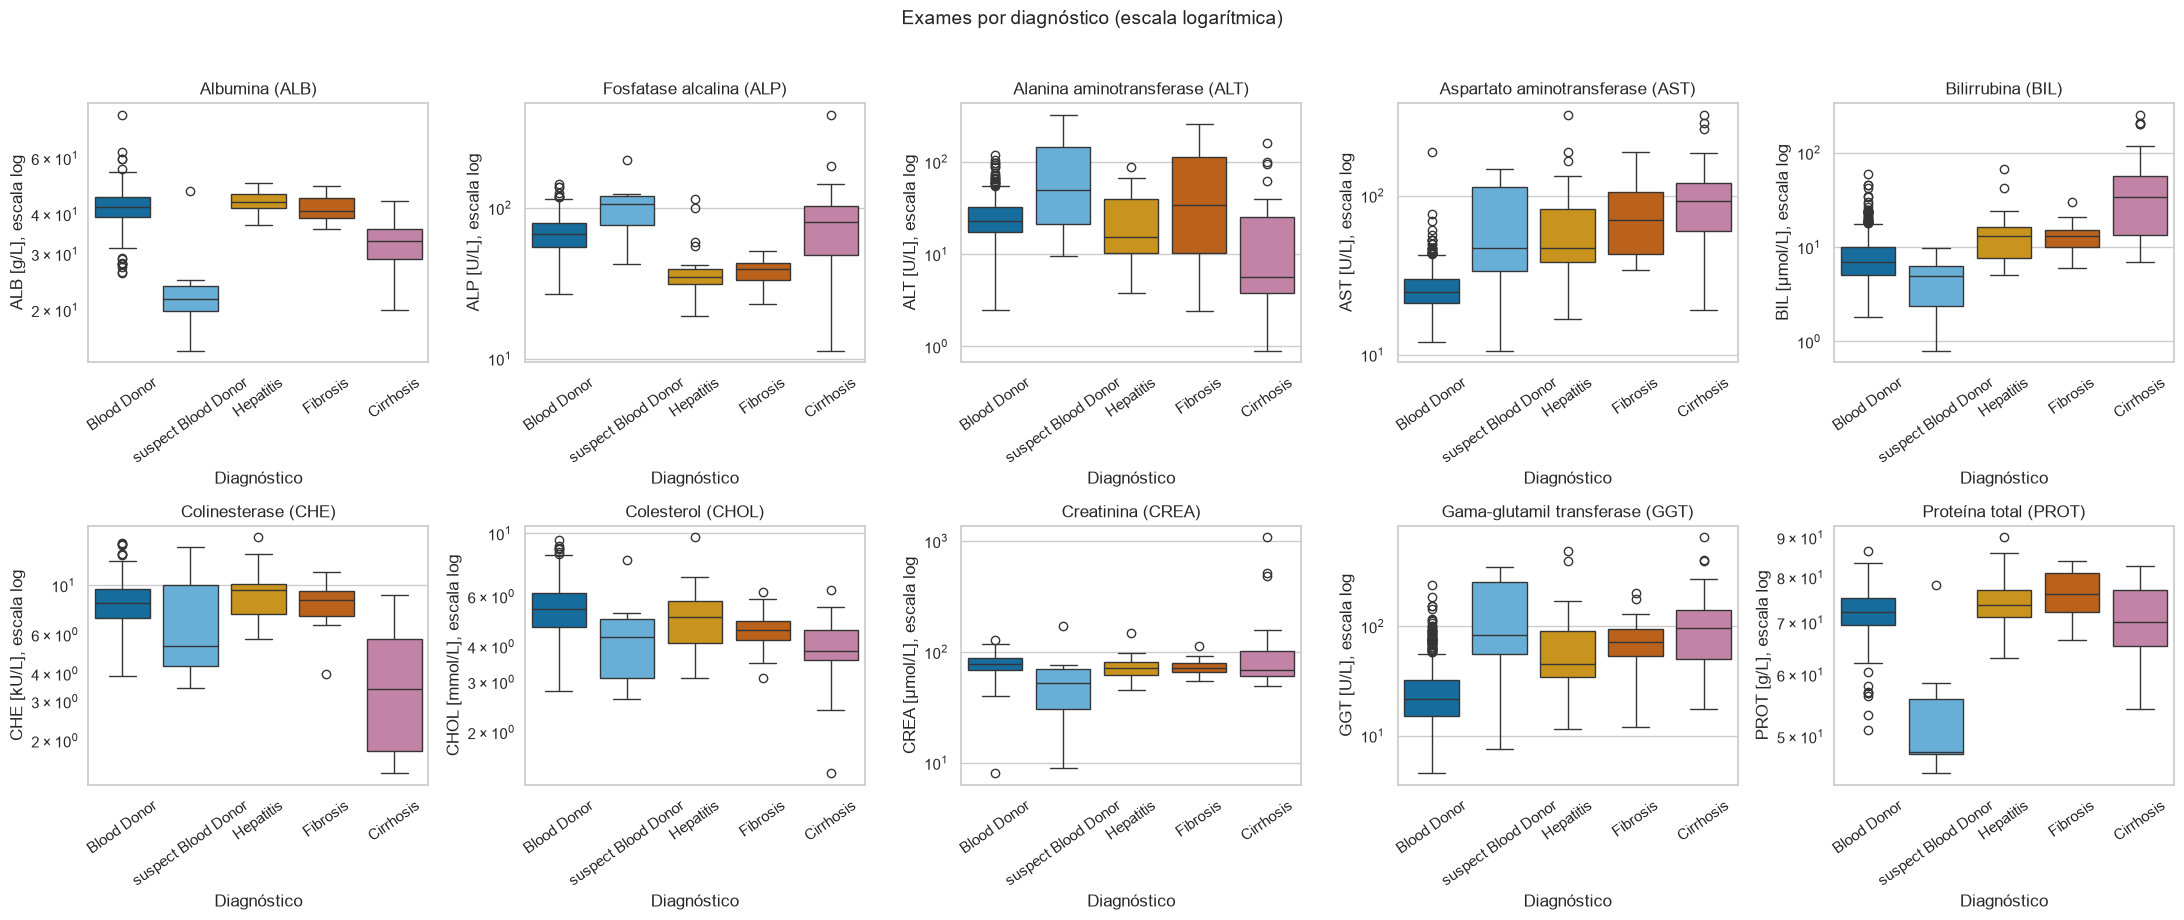

In [16]:
fig, axes = plt.subplots(2, 5, figsize=(22, 9))
for ax, col in zip(axes.flat, config.COLS_EXAMES):
    sns.boxplot(data=bruto, x='categoria', y=col, hue='categoria', order=config.ORDEM_CATEGORIAS,
                hue_order=config.ORDEM_CATEGORIAS, palette=PALETA, legend=False, ax=ax)
    ax.set_yscale('log')
    ax.set_title(config.NOMES[col])
    ax.set_xlabel('Diagnóstico')
    ax.set_ylabel(f'{col.upper()} [{config.UNIDADES[col]}], escala log')
    ax.tick_params(axis='x', rotation=35)
fig.suptitle('Exames por diagnóstico (escala logarítmica)', fontsize=14, y=1.02)
fig.tight_layout()
salvar(fig, 'eda_exames_por_diagnostico_log')
plt.show()

In [17]:
print('Valores mais extremos de cada exame (5 maiores):')
pd.concat({
    col: bruto.nlargest(5, col)[['categoria', col]].reset_index(drop=True)
    for col in config.COLS_EXAMES
}, axis=1)

Valores mais extremos de cada exame (5 maiores):


alb                        alp                         alt         \
     categoria   alb            categoria    alp            categoria    alt   
0  Blood Donor  82.2            Cirrhosis  416.6  suspect Blood Donor  325.3   
1  Blood Donor  62.9  suspect Blood Donor  208.2             Fibrosis  258.0   
2  Blood Donor  59.8            Cirrhosis  190.7  suspect Blood Donor  208.8   
3  Blood Donor  59.7          Blood Donor  145.0             Fibrosis  164.0   
4  Blood Donor  55.4            Cirrhosis  143.1            Cirrhosis  159.0   

           ast               bil                 che                chol  \
     categoria    ast  categoria    bil    categoria    che    categoria   
0    Hepatitis  324.0  Cirrhosis  254.0    Hepatitis  16.41    Hepatitis   
1    Cirrhosis  319.8  Cirrhosis  209.0  Blood Donor  15.43  Blood Donor   
2    Cirrhosis  285.8  Cirrhosis  200.0  Blood Donor  15.40  Blood Donor   
3    Cirrhosis  263.1  Cirrhosis  200.0  Blood Donor  15.40  Blood Donor   
4  Blood Donor  188.7  Cirrhosis  119.0  Blood Donor  15.10  Blood Donor   

                        crea                ggt                prot        
   chol            categoria    crea  categoria    ggt    categoria  prot  
0  9.67            Cirrhosis  1079.1  Cirrhosis  650.9    Hepatitis  90.0  
1  9.43            Cirrhosis   519.0  Hepatitis  491.0  Blood Donor  86.5  
2  9.03            Cirrhosis   485.9  Cirrhosis  400.3    Hepatitis  86.0  
3  8.89  suspect Blood Donor   170.0  Cirrhosis  399.5     Fibrosis  84.0  
4  8.80            Cirrhosis   158.2  Hepatitis  392.2  Blood Donor  83.4

**Análise do grupo:**

_(escrever aqui)_

**Decisão do grupo sobre os outliers:** erro de medição ou caso real da doença? Tratamento escolhido
(`TRATAMENTO_OUTLIERS` em `preparacao.py`), com justificativa.

_(escrever aqui)_

## 4. Distribuições no dado preparado

In [18]:
df = preparacao.carregar_tratado()
QUALITATIVAS = preparacao.colunas_qualitativas(df)

print(f'{len(df)} linhas; ausentes restantes nos exames: {int(df[config.COLS_EXAMES].isna().sum().sum())}')
print('Variáveis qualitativas:', QUALITATIVAS)

615 linhas; ausentes restantes nos exames: 31
Variáveis qualitativas: ['categoria', 'sexo', 'faixa_etaria', 'ggt_nivel']


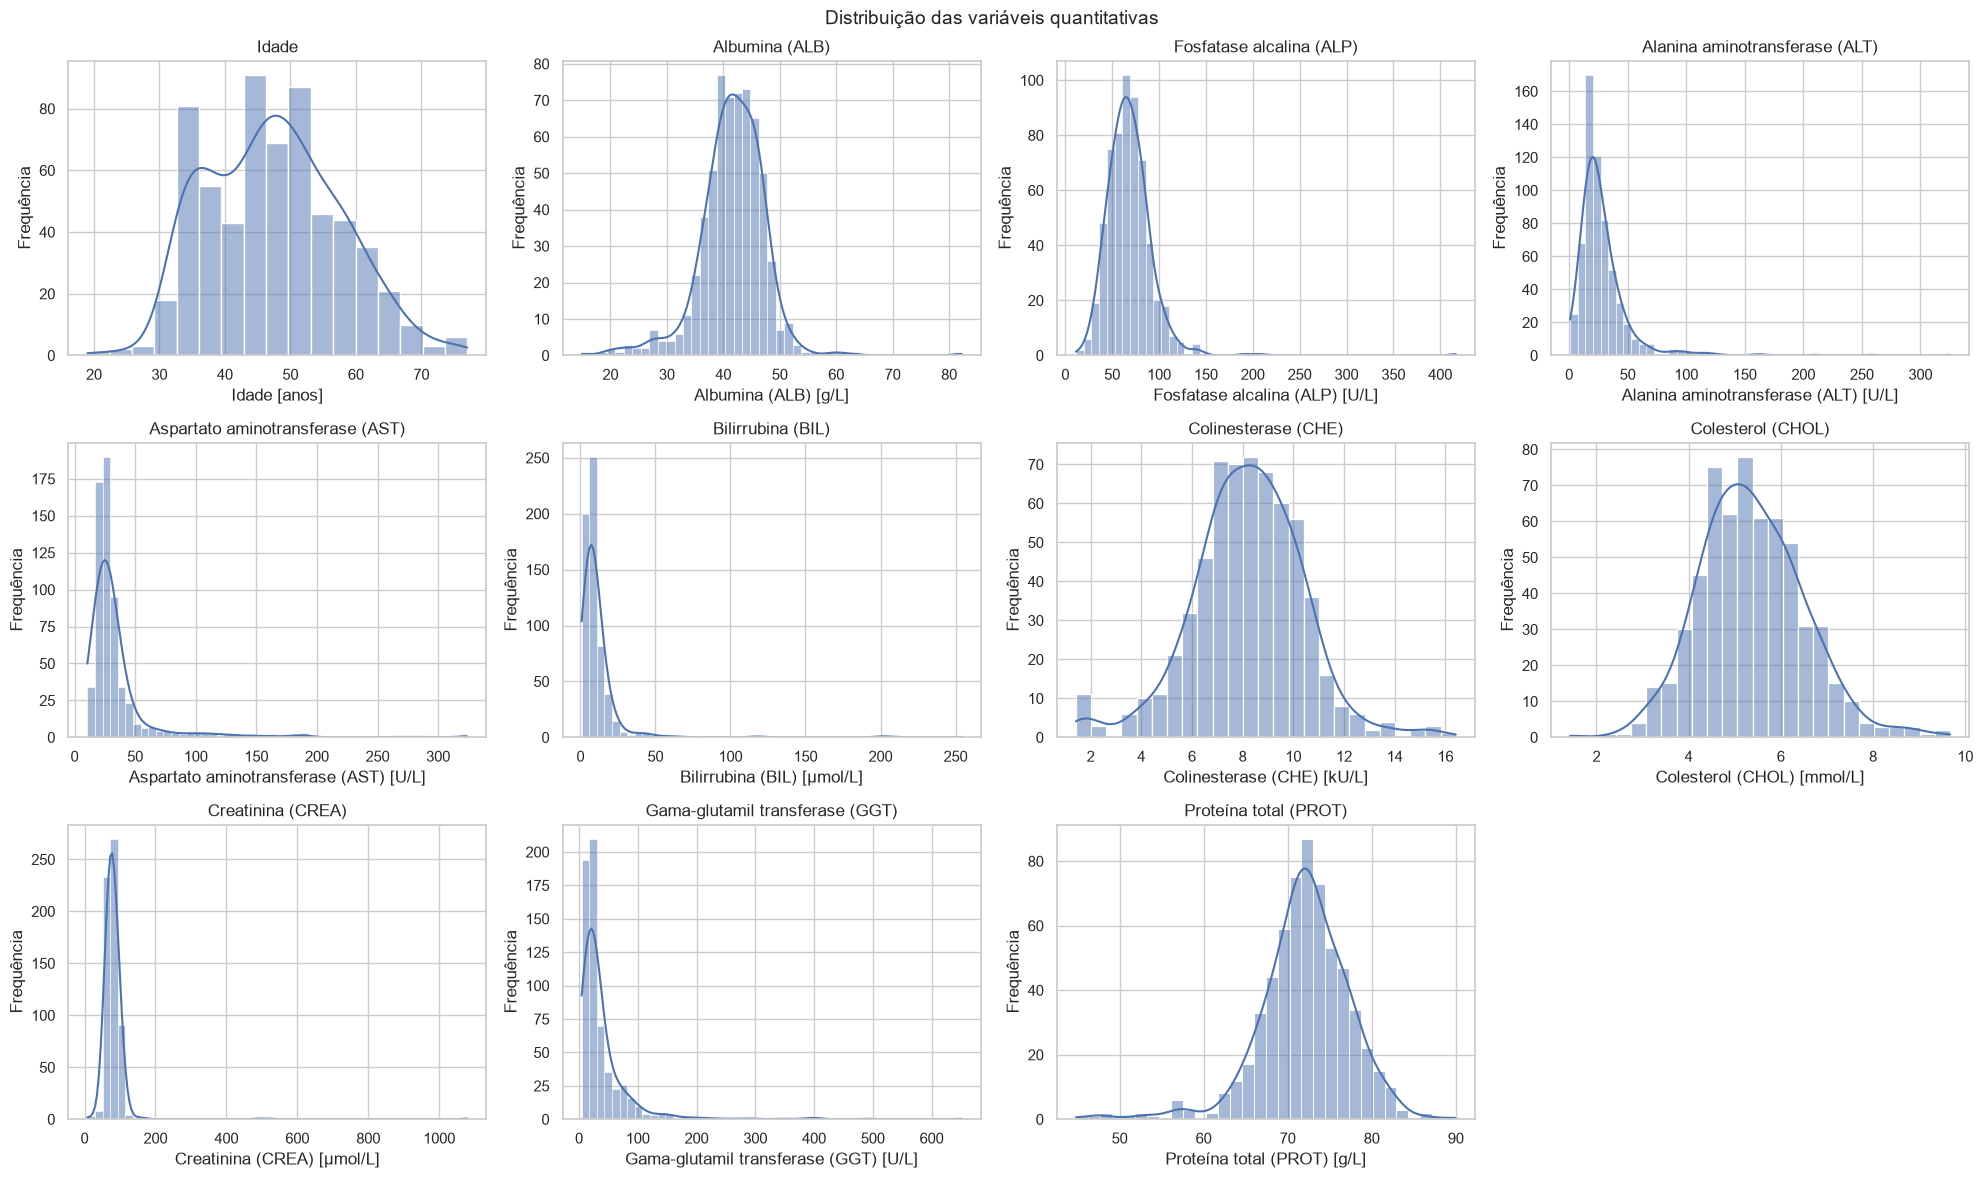

In [19]:
fig, axes = plt.subplots(3, 4, figsize=(20, 12))
for ax, col in zip(axes.flat, config.COLS_QUANTITATIVAS):
    sns.histplot(df[col], kde=True, ax=ax)
    ax.set_title(config.NOMES[col])
    ax.set_xlabel(config.rotulo(col))
    ax.set_ylabel('Frequência')
for ax in axes.flat[len(config.COLS_QUANTITATIVAS):]:
    ax.set_visible(False)
fig.suptitle('Distribuição das variáveis quantitativas', fontsize=14)
fig.tight_layout()
salvar(fig, 'eda_hist_quantitativas')
plt.show()

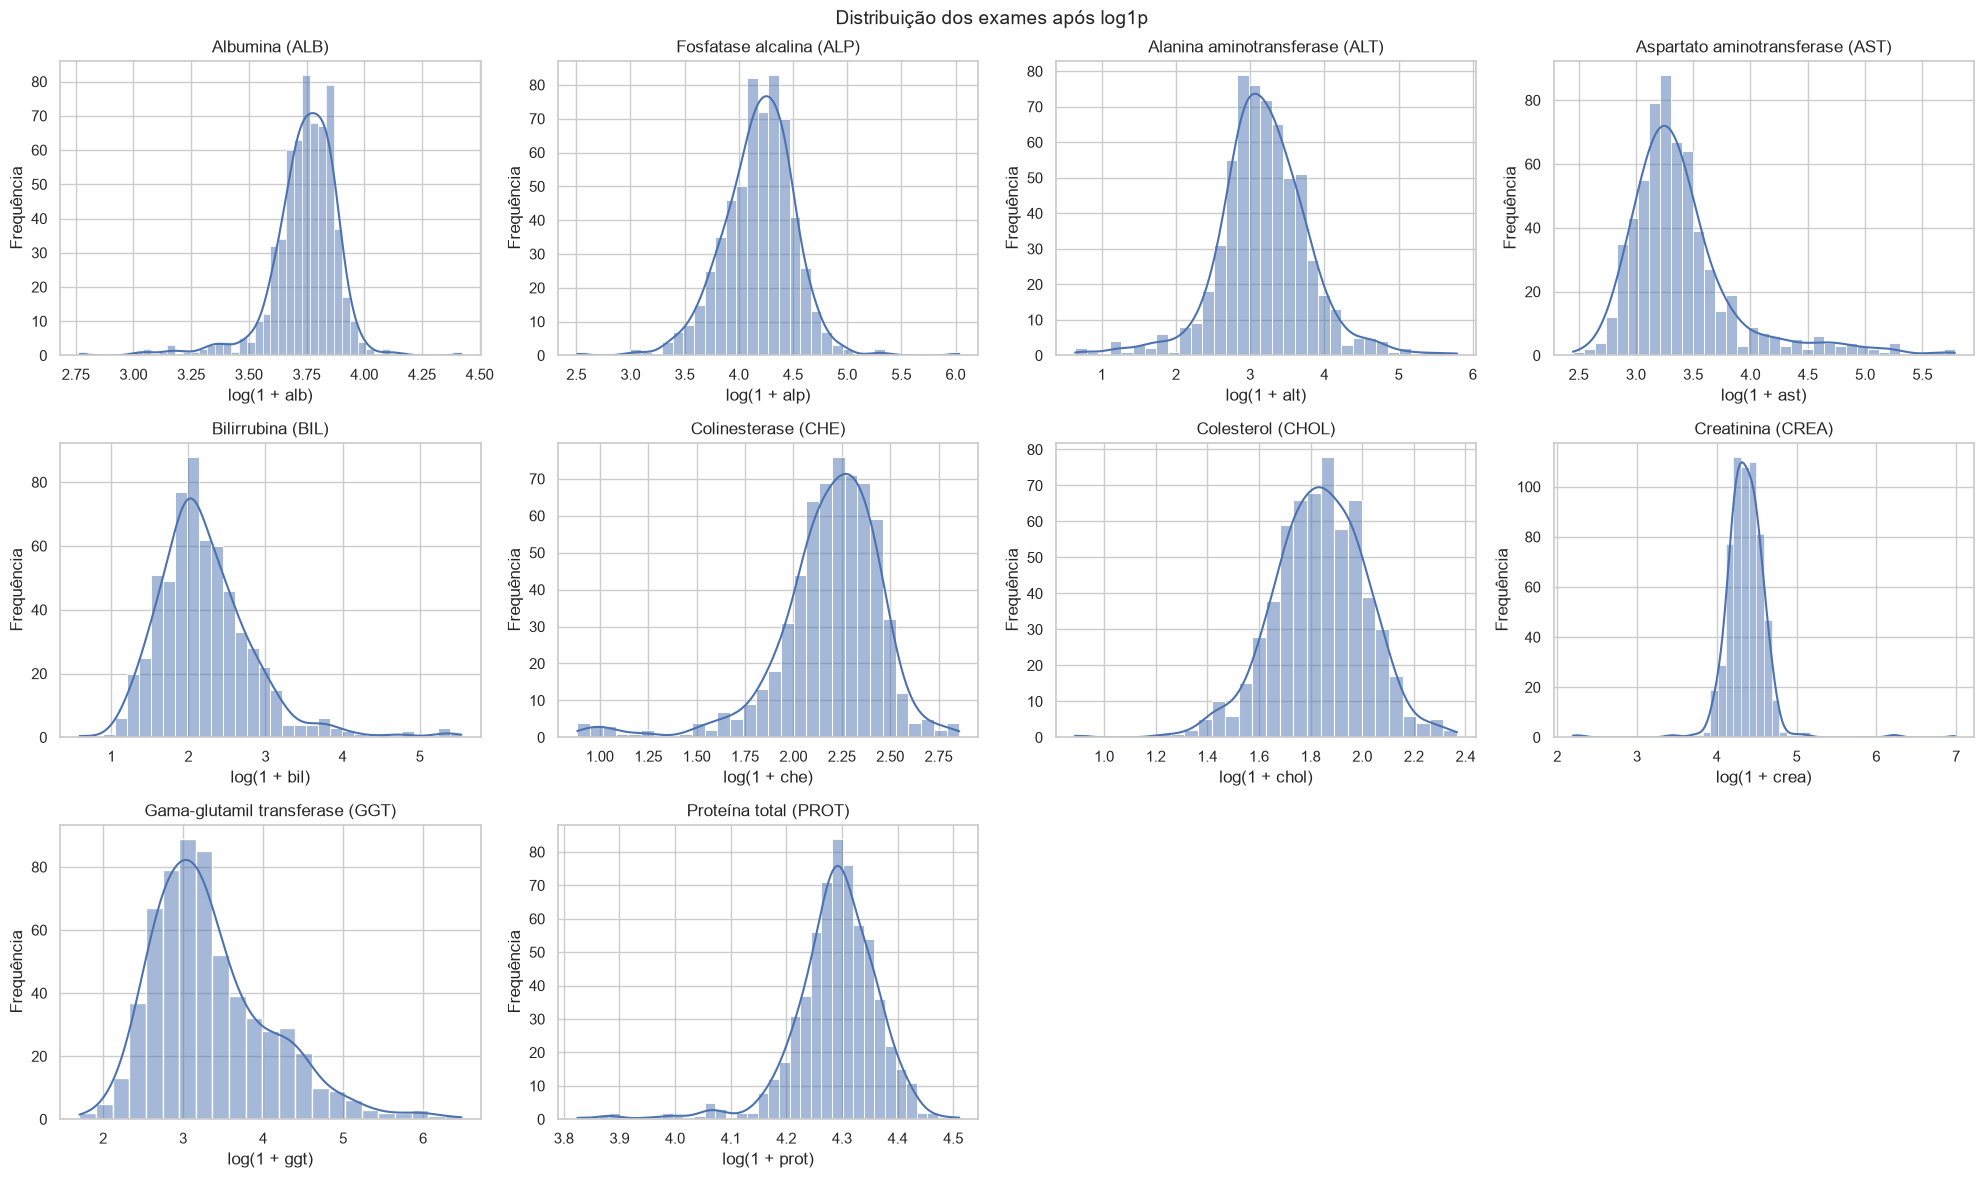

In [20]:
fig, axes = plt.subplots(3, 4, figsize=(20, 12))
for ax, col in zip(axes.flat, config.COLS_EXAMES):
    sns.histplot(np.log1p(df[col]), kde=True, ax=ax)
    ax.set_title(config.NOMES[col])
    ax.set_xlabel(f'log(1 + {col})')
    ax.set_ylabel('Frequência')
for ax in axes.flat[len(config.COLS_EXAMES):]:
    ax.set_visible(False)
fig.suptitle('Distribuição dos exames após log1p', fontsize=14)
fig.tight_layout()
salvar(fig, 'eda_hist_exames_log')
plt.show()

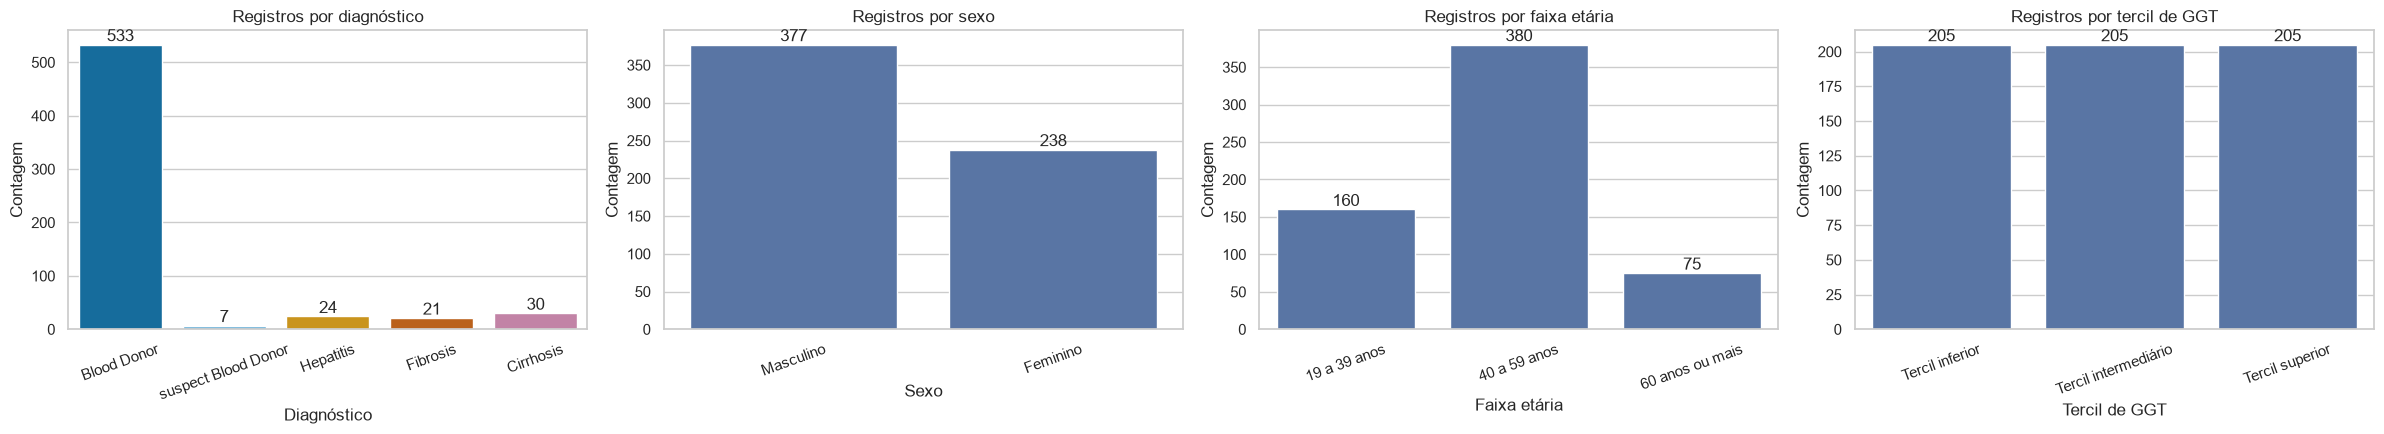

In [21]:
fig, axes = plt.subplots(1, len(QUALITATIVAS), figsize=(6 * len(QUALITATIVAS), 4.5), squeeze=False)
for ax, col in zip(axes.flat, QUALITATIVAS):
    contagem = df[col].value_counts().reindex(df[col].cat.categories)
    rotulos = [config.ROTULOS_SEXO.get(v, v) for v in contagem.index] if col == 'sexo' else contagem.index
    paleta = PALETA if col == 'categoria' else None
    sns.barplot(x=rotulos, y=contagem.values, hue=rotulos if paleta else None, palette=paleta, legend=False, ax=ax)
    for barras in ax.containers:
        ax.bar_label(barras)
    nome = config.rotulo(col)
    ax.set_title(f'Registros por {nome[0].lower() + nome[1:]}')
    ax.set_xlabel(config.rotulo(col))
    ax.set_ylabel('Contagem')
    ax.tick_params(axis='x', rotation=20)
fig.tight_layout()
salvar(fig, 'eda_contagem_qualitativas')
plt.show()

### Variáveis discretizadas

Novas qualitativas criadas a partir de quantitativas, conforme `DISCRETIZACOES` em `preparacao.py`.
`pd.cut` usa limites fixos; `pd.qcut` cria grupos de tamanho igual, com limites que dependem da amostra.

In [22]:
if not preparacao.DISCRETIZACOES:
    print('Nenhuma discretização definida em preparacao.DISCRETIZACOES.')
else:
    display(pd.DataFrame(preparacao.DISCRETIZACOES).T)
    for nova, regra in preparacao.DISCRETIZACOES.items():
        resumo = df.groupby(nova, observed=False)[regra['origem']].agg(['count', 'min', 'max'])
        resumo['pct'] = (resumo['count'] / resumo['count'].sum() * 100).round(1)
        print(f'--- {nova} (origem: {regra["origem"]}, técnica: {regra["tecnica"]})')
        display(resumo)

,origem,tecnica,limites,rotulos
faixa_etaria,idade,cut,"[19, 39, 59, inf]","[19 a 39 anos, 40 a 59 anos, 60 anos ou mais]"
ggt_nivel,ggt,qcut,3,"[Tercil inferior, Tercil intermediário, Tercil..."


--- faixa_etaria (origem: idade, técnica: cut)


,count,min,max,pct
faixa_etaria,,,,
19 a 39 anos,160,19,39,26.0
40 a 59 anos,380,40,59,61.8
60 anos ou mais,75,60,77,12.2


--- ggt_nivel (origem: ggt, técnica: qcut)


,count,min,max,pct
ggt_nivel,,,,
Tercil inferior,205,4.5,18.2,33.3
Tercil intermediário,205,18.3,31.5,33.3
Tercil superior,205,31.8,650.9,33.3


In [23]:
for nova in preparacao.DISCRETIZACOES:
    print(f'--- {nova} × diagnóstico (% dentro de cada diagnóstico)')
    display(pd.crosstab(df['categoria'], df[nova], normalize='index').mul(100).round(1))

--- faixa_etaria × diagnóstico (% dentro de cada diagnóstico)


faixa_etaria,19 a 39 anos,40 a 59 anos,60 anos ou mais
categoria,,,
Blood Donor,26.5,61.9,11.6
suspect Blood Donor,0.0,71.4,28.6
Hepatitis,58.3,37.5,4.2
Fibrosis,14.3,66.7,19.0
Cirrhosis,6.7,73.3,20.0


--- ggt_nivel × diagnóstico (% dentro de cada diagnóstico)


ggt_nivel,Tercil inferior,Tercil intermediário,Tercil superior
categoria,,,
Blood Donor,37.7,37.0,25.3
suspect Blood Donor,14.3,0.0,85.7
Hepatitis,4.2,16.7,79.2
Fibrosis,4.8,9.5,85.7
Cirrhosis,3.3,6.7,90.0


**Análise do grupo:**

_(escrever aqui)_

## 5. Relações

### Quantitativa × quantitativa

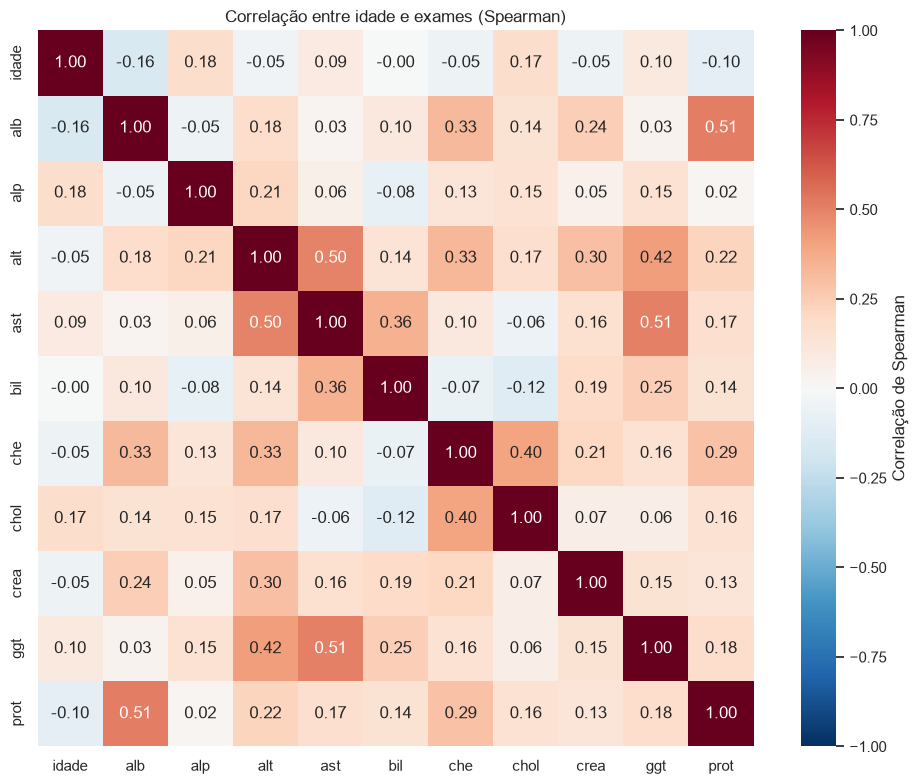

In [24]:
corr = df[config.COLS_QUANTITATIVAS].corr(method='spearman')

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, square=True, ax=ax,
            cbar_kws={'label': 'Correlação de Spearman'})
ax.set_title('Correlação entre idade e exames (Spearman)')
fig.tight_layout()
salvar(fig, 'eda_correlacao_spearman')
plt.show()

### Quantitativa × qualitativa (razão de correlação η)

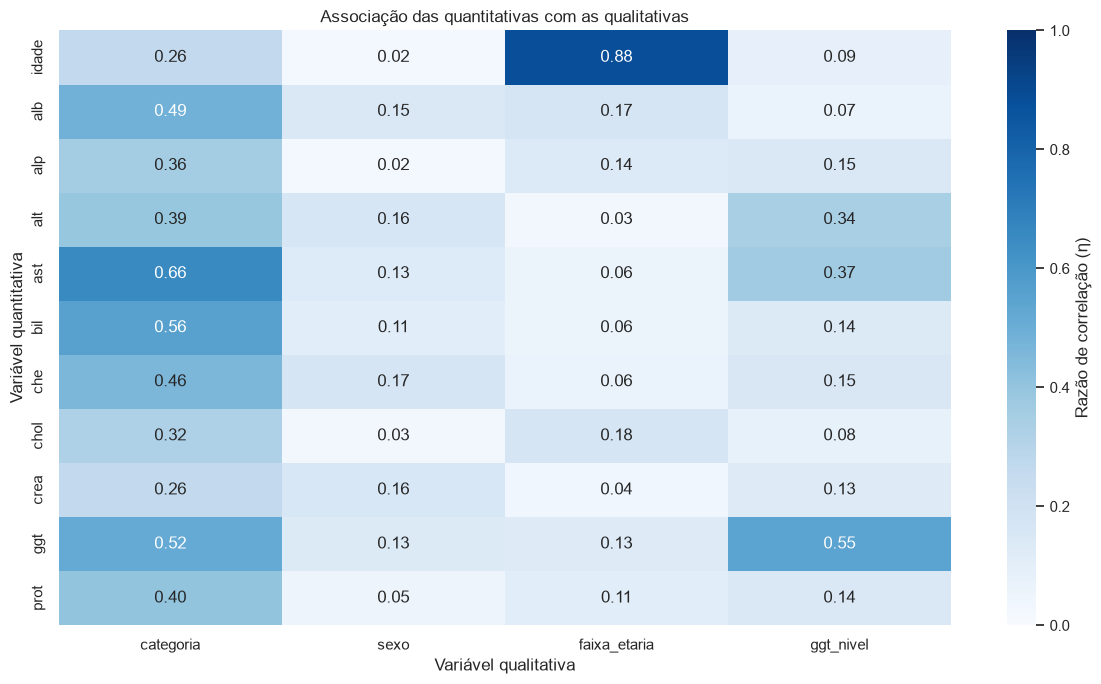

In [25]:
def razao_correlacao(categorias, valores):
    grupos = valores.groupby(categorias, observed=True)
    media = valores.mean()
    ss_entre = (grupos.count() * (grupos.mean() - media) ** 2).sum()
    ss_total = ((valores - media) ** 2).sum()
    return np.sqrt(ss_entre / ss_total)


matriz_eta = pd.DataFrame({
    cat: {num: razao_correlacao(df[cat], df[num]) for num in config.COLS_QUANTITATIVAS}
    for cat in QUALITATIVAS
})

fig, ax = plt.subplots(figsize=(2.5 * len(QUALITATIVAS) + 2, 7))
sns.heatmap(matriz_eta, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1, ax=ax,
            cbar_kws={'label': 'Razão de correlação (η)'})
ax.set_title('Associação das quantitativas com as qualitativas')
ax.set_xlabel('Variável qualitativa')
ax.set_ylabel('Variável quantitativa')
fig.tight_layout()
salvar(fig, 'eda_razao_correlacao')
plt.show()

In [26]:
df.groupby('categoria', observed=True)[config.COLS_QUANTITATIVAS].median().round(2)

,idade,alb,alp,alt,ast,bil,che,chol,crea,ggt,prot
categoria,,,,,,,,,,,
Blood Donor,47.0,42.2,66.70,23.10,24.8,6.9,8.35,5.40,78.00,21.40,72.20
suspect Blood Donor,55.0,21.6,106.00,49.20,46.7,4.9,5.33,4.30,52.00,83.00,47.80
Hepatitis,37.0,43.5,34.60,15.20,47.2,13.0,9.51,5.06,72.25,45.55,73.65
Fibrosis,51.0,41.0,39.55,34.00,70.0,13.0,8.59,4.58,71.40,72.20,76.10
Cirrhosis,56.0,33.0,80.05,5.65,92.9,34.0,3.42,3.87,68.50,96.35,70.00


In [27]:
df.groupby('sexo', observed=True)[config.COLS_QUANTITATIVAS].median().round(2)

,idade,alb,alp,alt,ast,bil,che,chol,crea,ggt,prot
sexo,,,,,,,,,,,
m,47.0,42.9,66.7,26.30,28.0,8.50,8.62,5.28,83.0,26.9,72.6
f,48.0,40.1,64.3,18.35,22.8,6.15,7.67,5.30,68.0,17.8,71.9


### Qualitativa × qualitativa

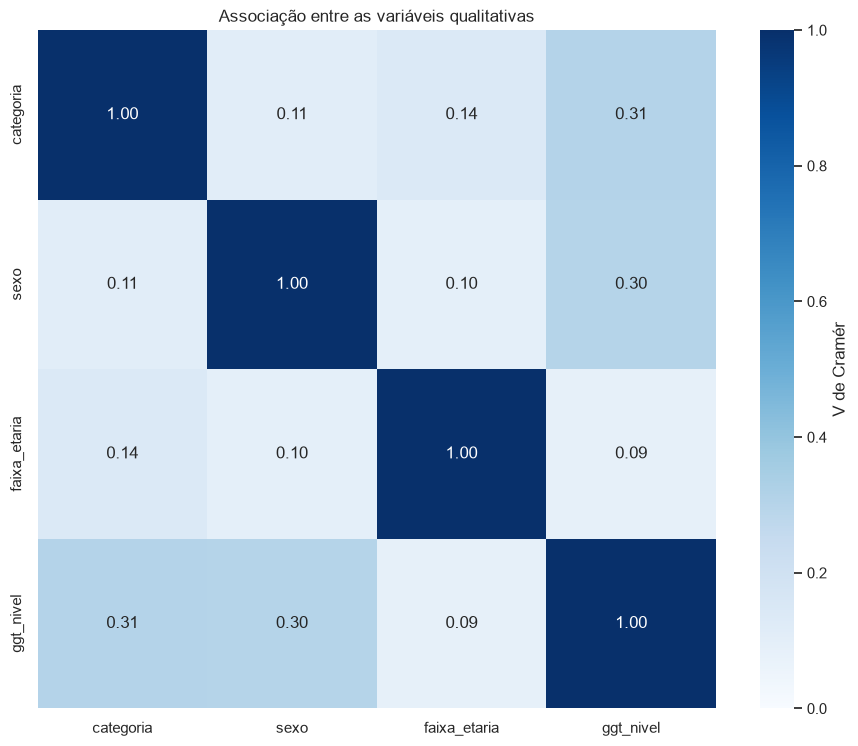

In [28]:
def cramers_v(x, y):
    tabela = pd.crosstab(x, y).to_numpy()
    n = tabela.sum()
    esperado = tabela.sum(axis=1, keepdims=True) @ tabela.sum(axis=0, keepdims=True) / n
    chi2 = ((tabela - esperado) ** 2 / esperado).sum()
    r, k = tabela.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1)))


matriz_v = pd.DataFrame(
    [[cramers_v(df[a], df[b]) for b in QUALITATIVAS] for a in QUALITATIVAS],
    index=QUALITATIVAS, columns=QUALITATIVAS,
)

fig, ax = plt.subplots(figsize=(1.6 * len(QUALITATIVAS) + 3, 1.4 * len(QUALITATIVAS) + 2))
sns.heatmap(matriz_v, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1, square=True, ax=ax,
            cbar_kws={'label': 'V de Cramér'})
ax.set_title('Associação entre as variáveis qualitativas')
fig.tight_layout()
salvar(fig, 'eda_cramers_v')
plt.show()

In [29]:
pd.crosstab(df['categoria'], df['sexo'], normalize='index').mul(100).round(1)

sexo,m,f
categoria,,
Blood Donor,59.7,40.3
suspect Blood Donor,85.7,14.3
Hepatitis,83.3,16.7
Fibrosis,61.9,38.1
Cirrhosis,66.7,33.3


**Análise do grupo:**

_(escrever aqui)_

## 6. Achados que viram as explanatórias

**Pergunta de pesquisa, público-alvo e achados que sustentam as 2 visualizações explanatórias (texto do grupo):**

_(escrever aqui)_